## Ejemplos oficiales desde xgboost.com

In [20]:
# XGBoosting.com
# Fit an XGBoost Model for Binary Classification using scikit-learn API
from sklearn.datasets import make_classification
from xgboost import XGBClassifier

# Generate a synthetic dataset with 2 classes
X, y = make_classification(n_samples=1000, n_features=20, n_informative=2, n_redundant=10, random_state=42)

# Initialize XGBClassifier
model = XGBClassifier(objective='binary:logistic', random_state=42)

# Fit the model to training data
model.fit(X, y)

# Make predictions with the fit model
predictions = model.predict(X)
print(predictions[:5])

[0 0 0 1 1]


In [21]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import xgboost as xgb

# Load the breast cancer dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define XGBClassifier model parameters
params = {
    'objective': 'binary:logistic',
    'max_depth': 3,
    'learning_rate': 0.1,
    'n_estimators': 100,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'random_state': 42
}

# Instantiate XGBClassifier with the parameters
model = xgb.XGBClassifier(**params)

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print(f"Confusion Matrix:\n{confusion}")
print(f"Classification Report:\n{report}")

Accuracy: 0.96
Confusion Matrix:
[[40  3]
 [ 1 70]]
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.95        43
           1       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [22]:
# regresion
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb

# Load the Housing dataset
data = fetch_california_housing()
X, y = data.data, data.target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define XGBRegressor model parameters
params = {
    'objective': 'reg:squarederror',
    'max_depth': 3,
    'learning_rate': 0.1,
    'n_estimators': 100,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'random_state': 42
}

# Instantiate XGBRegressor with the parameters
model = xgb.XGBRegressor(**params)

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

Mean Squared Error: 0.29
R-squared: 0.78


### Clasificación (breast cancer)
Ejemplo completo de clasificación con XGBoost (sklearn API) usando el dataset breast cancer

c:\Users\PATRICIO\Documents\github\ciencia-de-datos\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:18:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Accuracy: 0.9650
ROC AUC: 0.9952

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.92      0.95        53
           1       0.96      0.99      0.97        90

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143

Confusion Matrix:
[[49  4]
 [ 1 89]]


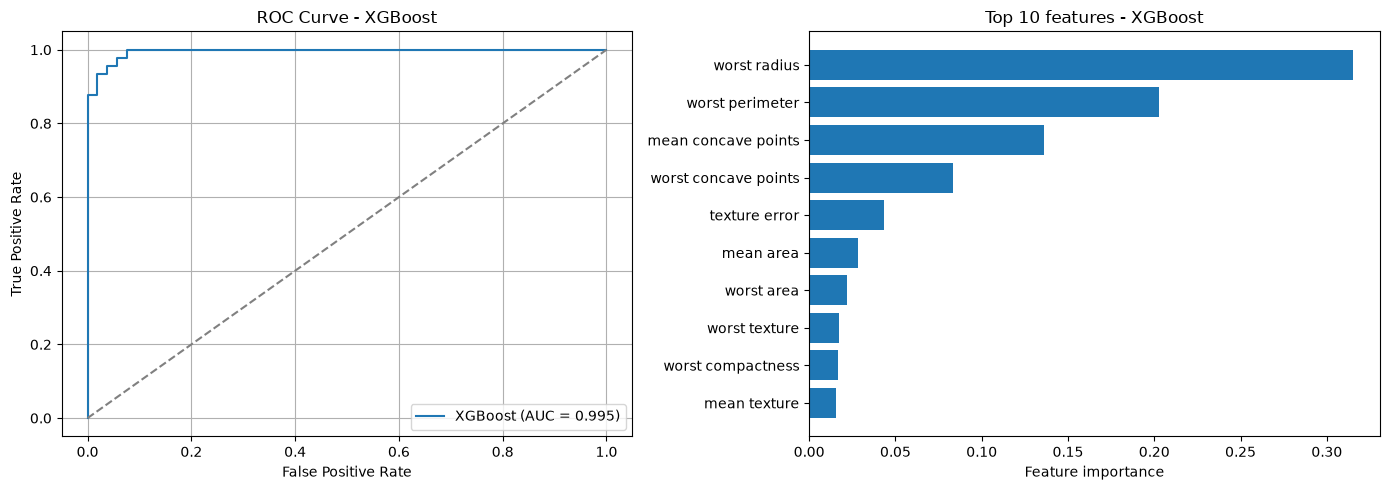

In [29]:
# Ejemplo completo de clasificación con XGBoost (sklearn API) usando el dataset breast cancer
import sys
import subprocess
from xgboost import XGBClassifier
import xgboost as xgb
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Intentar importar xgboost, instalar si no está disponible
#try:
#except Exception:
#    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)


# Cargar datos
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names

# División train/test (estratificado)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Escalado (recomendado para XGBoost no es obligatorio, pero es útil para comparativas)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Definir el clasificador XGBoost (sklearn wrapper)
clf = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    use_label_encoder=False,  # evita warning en versiones recientes
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

# Entrenar con early stopping monitorizando el conjunto de validación (test)
# Algunas versiones del wrapper sklearn de XGBoost no aceptan `callbacks` en fit().
# Usamos el argumento compatible `early_stopping_rounds` en su lugar.
clf.fit(
    X_train_s,
    y_train,
    eval_set=[(X_test_s, y_test)],
    verbose=False,
)

# Predicciones y probabilidades
y_pred = clf.predict(X_test_s)
y_proba = clf.predict_proba(X_test_s)[:, 1]

# Métricas de evaluación
acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
print(f"Accuracy: {acc:.4f}")
print(f"ROC AUC: {roc_auc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Curva ROC
ax1.plot(fpr, tpr, label=f"XGBoost (AUC = {roc_auc:.3f})")
ax1.plot([0, 1], [0, 1], "--", color="gray")
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")
ax1.set_title("ROC Curve - XGBoost")
ax1.legend()
ax1.grid(True)

# Importancia de características (top 10)
importances = clf.feature_importances_
idxs = np.argsort(importances)[::-1][:10]
top_feats = feature_names[idxs]
top_vals = importances[idxs]

ax2.barh(top_feats[::-1], top_vals[::-1])
ax2.set_title("Top 10 features - XGBoost")
ax2.set_xlabel("Feature importance")

plt.tight_layout()
plt.show()

### Regresion
Análisis de Regresión con XGBoost (Extreme Gradient Boosting)

Utilizaremos el conjunto de datos clínico real Diabetes Dataset (Bradley Efron, Trevor Hastie, Iain Johnstone y Robert Tibshirani, 2004), integrado nativamente en sklearn.datasets.load_diabetes.

Problema: Predecir cuantitativamente la progresión de la enfermedad tras un año del diagnóstico basal (medida continua en escala de 25 a 346) a partir de 10 mediciones cuantitativas: Edad, Sexo, Índice de Masa Corporal (IMC), Presión Arterial y 6 análisis séricos de laboratorio (s1 a s6).

EVALUACIÓN DE REGRESIÓN: XGBOOST REGRESSOR (TEST SET)
Coeficiente de Determinación (R²) : 0.5054 (50.5% varianza explicada)
Error Cuadrático Medio (RMSE)     : 52.30 puntos
Error Absoluto Medio (MAE)        : 41.42 puntos


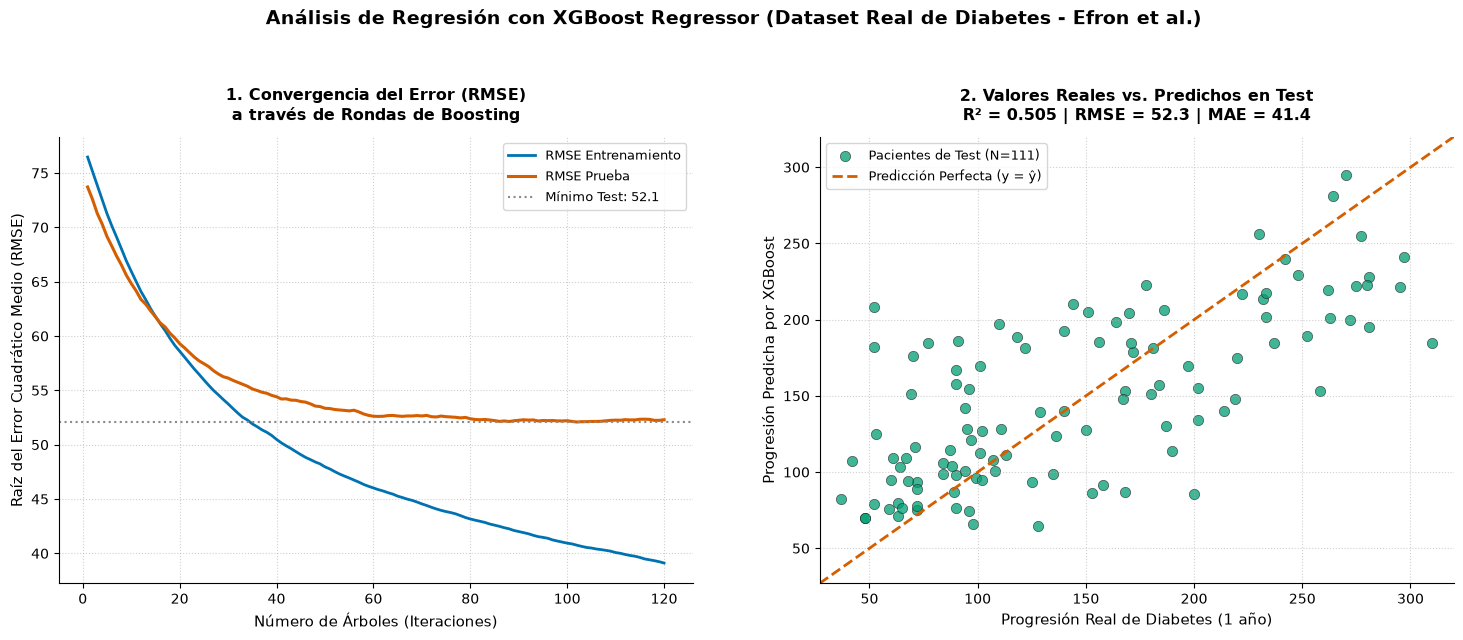

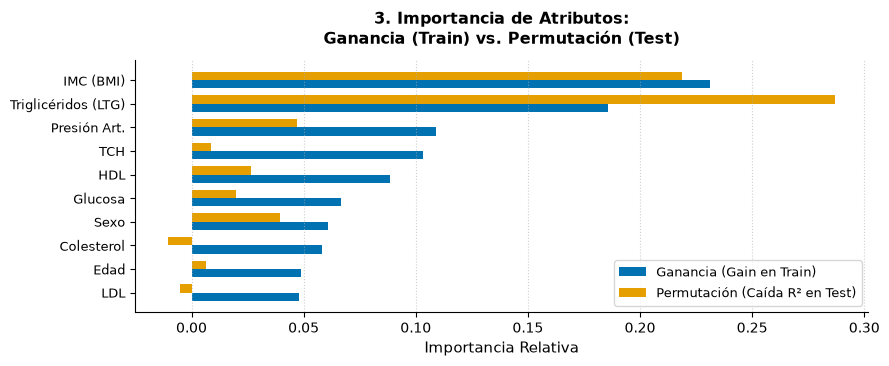

<Figure size 640x480 with 0 Axes>

In [19]:
"""
XGBoost para Regresión y Monitoreo de Convergencia.
Dataset Real: Diabetes Dataset (Efron et al., 2004 / Scikit-Learn).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
import xgboost as xgb

# ==============================================================================
# 1. Ingesta de Datos y Partición de Prueba Independiente
# ==============================================================================
diab = load_diabetes()
X = pd.DataFrame(diab.data, columns=diab.feature_names)

# Renombrado de variables para interpretación clínica directa
nombres_clinicos = {
    'age': 'Edad', 'sex': 'Sexo', 'bmi': 'IMC (BMI)', 'bp': 'Presión Art.',
    's1': 'Colesterol', 's2': 'LDL', 's3': 'HDL', 's4': 'TCH',
    's5': 'Triglicéridos (LTG)', 's6': 'Glucosa'
}
X = X.rename(columns=nombres_clinicos)
y = diab.target

# Partición 75% Entrenamiento y 25% Prueba independiente
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42)

# ==============================================================================
# 2. Configuración y Entrenamiento de XGBRegressor con Monitoreo
# ==============================================================================
modelo_xgb = xgb.XGBRegressor(
    n_estimators=120,        # Número de árboles secuenciales
    learning_rate=0.04,      # Factor de contracción (shrinkage eta)
    max_depth=3,             # Árboles poco profundos para regularizar sesgo/varianza
    reg_lambda=2.0,          # Regularización L2 sobre los pesos de las hojas
    reg_alpha=0.3,           # Regularización L1 (sparsity)
    subsample=0.8,           # 80% de observaciones por árbol
    colsample_bytree=0.8,    # 80% de variables evaluadas por árbol
    eval_metric='rmse',      # Métrica de monitoreo
    random_state=42,
    n_jobs=-1
)

# Monitoreo simultáneo en entrenamiento y prueba para auditar sobreajuste
eval_set = [(X_tr, y_tr), (X_te, y_te)]
modelo_xgb.fit(X_tr, y_tr, eval_set=eval_set, verbose=False)

# ==============================================================================
# 3. Inferencia y Evaluación en el Conjunto de Test
# ==============================================================================
y_pred = modelo_xgb.predict(X_te)
r2_val = r2_score(y_te, y_pred)
rmse_val = root_mean_squared_error(y_te, y_pred)
mae_val = mean_absolute_error(y_te, y_pred)

print("=" * 65)
print("EVALUACIÓN DE REGRESIÓN: XGBOOST REGRESSOR (TEST SET)")
print("=" * 65)
print(f"Coeficiente de Determinación (R²) : {r2_val:.4f} ({r2_val*100:.1f}% varianza explicada)")
print(f"Error Cuadrático Medio (RMSE)     : {rmse_val:.2f} puntos")
print(f"Error Absoluto Medio (MAE)        : {mae_val:.2f} puntos")

# ==============================================================================
# 4. Cálculo de Importancia de Atributos: Ganancia (Gain) vs. Permutación
# ==============================================================================
importancias_gain = modelo_xgb.feature_importances_
perm_res = permutation_importance(modelo_xgb, X_te, y_te, n_repeats=10, random_state=42, scoring='r2')

top_idx = np.argsort(importancias_gain)
vars_ordenadas = [X.columns[i] for i in top_idx]

# ==============================================================================
# 5. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
# ==============================================================================
historial = modelo_xgb.evals_result()
rmse_tr_hist = historial['validation_0']['rmse']
rmse_te_hist = historial['validation_1']['rmse']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5.8), facecolor='white')

# Panel 1: Curva de Convergencia del Error (RMSE)
ax1.set_facecolor('white')
rondas = range(1, len(rmse_tr_hist) + 1)
ax1.plot(rondas, rmse_tr_hist, color='#0072b2', linewidth=2, label='RMSE Entrenamiento')
ax1.plot(rondas, rmse_te_hist, color='#d55e00', linewidth=2.2, label='RMSE Prueba')
ax1.axhline(min(rmse_te_hist), color='#8a8a8a', linestyle=':', label=f'Mínimo Test: {min(rmse_te_hist):.1f}')
ax1.set_title("1. Convergencia del Error (RMSE)\na través de Rondas de Boosting", fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Número de Árboles (Iteraciones)", fontsize=10.5)
ax1.set_ylabel("Raíz del Error Cuadrático Medio (RMSE)", fontsize=10.5)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Panel 2: Valores Reales vs. Predichos
ax2.set_facecolor('white')
ax2.scatter(y_te, y_pred, color='#009e73', alpha=0.75, edgecolors='#222222', linewidth=0.5, s=55, label='Pacientes de Test (N=111)')
min_v = min(y_te.min(), y_pred.min()) - 10
max_v = max(y_te.max(), y_pred.max()) + 10
ax2.plot([min_v, max_v], [min_v, max_v], color='#d55e00', linestyle='--', linewidth=2, label='Predicción Perfecta (y = ŷ)')
ax2.set_xlim(min_v, max_v)
ax2.set_ylim(min_v, max_v)
ax2.set_title(f"2. Valores Reales vs. Predichos en Test\nR² = {r2_val:.3f} | RMSE = {rmse_val:.1f} | MAE = {mae_val:.1f}", fontsize=11.5, fontweight='bold', pad=12)
ax2.set_xlabel("Progresión Real de Diabetes (1 año)", fontsize=10.5)
ax2.set_ylabel("Progresión Predicha por XGBoost", fontsize=10.5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='upper left', fontsize=9.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Panel 3: Importancia de Atributos (Gain vs. Permutación)
fig2, ax3 = plt.subplots(1, 1, figsize=(9, 4), facecolor='white')

ax3.set_facecolor('white')
y_pos = np.arange(len(vars_ordenadas))
h = 0.35
ax3.barh(y_pos - h/2, [importancias_gain[i] for i in top_idx], height=h, color='#0072b2', label='Ganancia (Gain en Train)')
ax3.barh(y_pos + h/2, [perm_res.importances_mean[i] for i in top_idx], height=h, color='#e69f00', label='Permutación (Caída R² en Test)')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(vars_ordenadas, fontsize=9.5)
ax3.set_xlabel("Importancia Relativa", fontsize=10.5)
ax3.set_title("3. Importancia de Atributos:\nGanancia (Train) vs. Permutación (Test)", fontsize=11.5, fontweight='bold', pad=12)
ax3.grid(True, axis='x', linestyle=':', alpha=0.6)
ax3.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

fig.suptitle("Análisis de Regresión con XGBoost Regressor (Dataset Real de Diabetes - Efron et al.)",
             fontsize=13.5, fontweight='bold', y=1.1)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# fig2.suptitle("Importancia de Atributos con XGBoost Regressor (Dataset Real de Diabetes - Efron et al.)",
#              fontsize=13.5, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


### Parada temprana

Dimensiones de trabajo -> Train: 264 | Validación: 89 | Test: 89
RESULTADOS DEL PROCEDIMIENTO DE PARADA TEMPRANA
Número total de árboles solicitados : 300
Iteración óptima seleccionada (t*)  : Ronda 132
Mejor RMSE en Validación            : 52.85 puntos
Ronda de interrupción física        : Ronda 147

Evaluación en Datos de Prueba Independientes (Test Set, N = 89):
Coeficiente R² : 0.4505 (45.1% varianza explicada)
RMSE           : 53.96 puntos
MAE            : 43.69 puntos


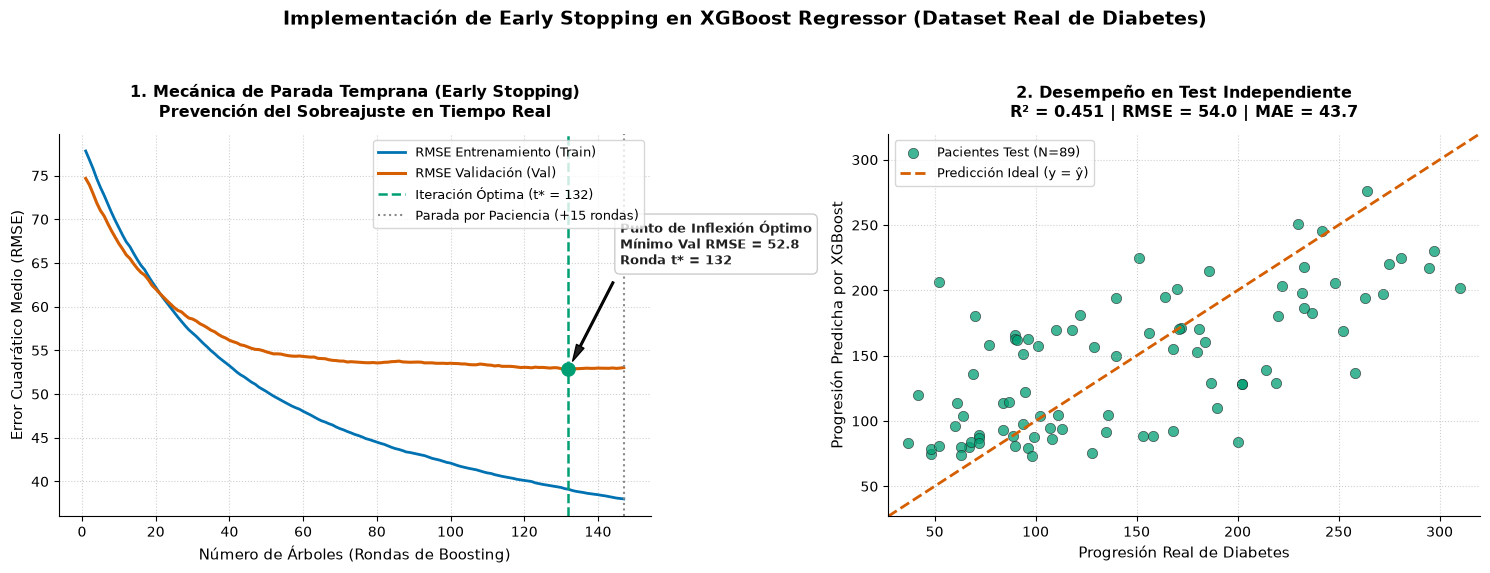

In [30]:
"""
Early Stopping (Parada temprana) en XGBoost Regressor.
Dataset Real: Diabetes Dataset (scikit-learn / Efron et al., 2004).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
import xgboost as xgb

# ==============================================================================
# 1. Ingesta y Partición en Tres Vías (Train, Val, Test)
# ==============================================================================
diab = load_diabetes()
X = pd.DataFrame(diab.data, columns=diab.feature_names)
nombres_clinicos = {
    'age': 'Edad', 'sex': 'Sexo', 'bmi': 'IMC (BMI)', 'bp': 'Presión Art.',
    's1': 'Colesterol', 's2': 'LDL', 's3': 'HDL', 's4': 'TCH',
    's5': 'Triglicéridos (LTG)', 's6': 'Glucosa'
}
X = X.rename(columns=nombres_clinicos)
y = diab.target

# Partición 80% (Train+Val) y 20% (Test final independiente)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
# Partición del 80% previo en 60% Train y 20% Val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42
)

print(f"Dimensiones de trabajo -> Train: {len(X_train)} | Validación: {len(X_val)} | Test: {len(X_test)}")

# ==============================================================================
# 2. Configuración y Ajuste de XGBoost con Early Stopping
# ==============================================================================
paciencia = 15

modelo_xgb_early = xgb.XGBRegressor(
    n_estimators=300,          # Techo intencionalmente sobredimensionado
    learning_rate=0.03,        # Tasa baja para observar convergencia progresiva
    max_depth=3,
    reg_lambda=1.5,            # Regularización L2
    reg_alpha=0.2,             # Regularización L1
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='rmse',
    early_stopping_rounds=paciencia,  # Activación de la parada temprana
    random_state=42,
    n_jobs=-1
)

# Monitoreo simultáneo de entrenamiento y validación
eval_set = [(X_train, y_train), (X_val, y_val)]
modelo_xgb_early.fit(
    X_train, y_train,
    eval_set=eval_set,
    verbose=False
)

iteracion_optima = modelo_xgb_early.best_iteration
mejor_rmse_val = modelo_xgb_early.best_score

print("=" * 65)
print("RESULTADOS DEL PROCEDIMIENTO DE PARADA TEMPRANA")
print("=" * 65)
print(f"Número total de árboles solicitados : 300")
print(f"Iteración óptima seleccionada (t*)  : Ronda {iteracion_optima + 1}")
print(f"Mejor RMSE en Validación            : {mejor_rmse_val:.2f} puntos")
print(f"Ronda de interrupción física        : Ronda {iteracion_optima + 1 + paciencia}")

# ==============================================================================
# 3. Evaluación en el Conjunto de Prueba Independiente (Test Set)
# ==============================================================================
# XGBoost aplica automáticamente el modelo de la 'best_iteration' al predecir
y_pred_test = modelo_xgb_early.predict(X_test)
r2_test = r2_score(y_test, y_pred_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)
mae_test = mean_absolute_error(y_test, y_pred_test)

print("\nEvaluación en Datos de Prueba Independientes (Test Set, N = 89):")
print(f"Coeficiente R² : {r2_test:.4f} ({r2_test*100:.1f}% varianza explicada)")
print(f"RMSE           : {rmse_test:.2f} puntos")
print(f"MAE            : {mae_test:.2f} puntos")

# ==============================================================================
# 4. Generación Gráfica del Punto de Parada y Dispersión
# ==============================================================================
historial = modelo_xgb_early.evals_result()
rmse_train_hist = historial['validation_0']['rmse']
rmse_val_hist = historial['validation_1']['rmse']
rondas = range(1, len(rmse_train_hist) + 1)
total_rondas = len(rmse_train_hist)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8), facecolor='white')

# Panel 1: Curva de Convergencia y Parada Temprana
ax1.set_facecolor('white')
ax1.plot(rondas, rmse_train_hist, color='#0072b2', linewidth=2, label='RMSE Entrenamiento (Train)')
ax1.plot(rondas, rmse_val_hist, color='#d55e00', linewidth=2.2, label='RMSE Validación (Val)')

# Líneas guía de corte óptimo
ax1.axvline(iteracion_optima + 1, color='#009e73', linestyle='--', linewidth=1.8,
            label=f'Iteración Óptima (t* = {iteracion_optima + 1})')
ax1.axvline(total_rondas, color='#8a8a8a', linestyle=':', linewidth=1.5,
            label=f'Parada por Paciencia (+{paciencia} rondas)')
ax1.scatter([iteracion_optima + 1], [mejor_rmse_val], color='#009e73', s=90, zorder=5)

ax1.annotate(
    f'Punto de Inflexión Óptimo\nMínimo Val RMSE = {mejor_rmse_val:.1f}\nRonda t* = {iteracion_optima + 1}',
    xy=(iteracion_optima + 1, mejor_rmse_val),
    xytext=(iteracion_optima + 15, mejor_rmse_val + 12),
    arrowprops=dict(facecolor='#222222', shrink=0.08, width=1.2, headwidth=6),
    fontweight='bold', fontsize=9.5, color='#222222',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#cccccc')
)

ax1.set_title("1. Mecánica de Parada Temprana (Early Stopping)\nPrevención del Sobreajuste en Tiempo Real", fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Número de Árboles (Rondas de Boosting)", fontsize=10.5)
ax1.set_ylabel("Error Cuadrático Medio (RMSE)", fontsize=10.5)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Panel 2: Desempeño en Test Independiente
ax2.set_facecolor('white')
ax2.scatter(y_test, y_pred_test, color='#009e73', alpha=0.75, edgecolors='#222222', linewidth=0.5, s=55, label='Pacientes Test (N=89)')
min_v = min(y_test.min(), y_pred_test.min()) - 10
max_v = max(y_test.max(), y_pred_test.max()) + 10
ax2.plot([min_v, max_v], [min_v, max_v], color='#d55e00', linestyle='--', linewidth=2, label='Predicción Ideal (y = ŷ)')
ax2.set_xlim(min_v, max_v)
ax2.set_ylim(min_v, max_v)

ax2.set_title(f"2. Desempeño en Test Independiente\nR² = {r2_test:.3f} | RMSE = {rmse_test:.1f} | MAE = {mae_test:.1f}", fontsize=11.5, fontweight='bold', pad=12)
ax2.set_xlabel("Progresión Real de Diabetes", fontsize=10.5)
ax2.set_ylabel("Progresión Predicha por XGBoost", fontsize=10.5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='upper left', fontsize=9.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

fig.suptitle("Implementación de Early Stopping en XGBoost Regressor (Dataset Real de Diabetes)", fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


### Prediccion de precios

Dimensiones del dataset: (20640, 9)

Estadísticas descriptivas (muestra de columnas clave):
          MedInc   HouseAge   AveRooms   AveOccup   Latitude  Longitude  \
count  20640.000  20640.000  20640.000  20640.000  20640.000  20640.000   
mean       3.871     28.639      5.429      3.071     35.632   -119.570   
std        1.900     12.586      2.474     10.386      2.136      2.004   
min        0.500      1.000      0.846      0.692     32.540   -124.350   
25%        2.563     18.000      4.441      2.430     33.930   -121.800   
50%        3.535     29.000      5.229      2.818     34.260   -118.490   
75%        4.743     37.000      6.052      3.282     37.710   -118.010   
max       15.000     52.000    141.909   1243.333     41.950   -114.310   

       MedHouseVal  
count    20640.000  
mean         2.069  
std          1.154  
min          0.150  
25%          1.196  
50%          1.797  
75%          2.647  
max          5.000  

Métricas Train -> MAE: 0.2958 (test) vs 0.

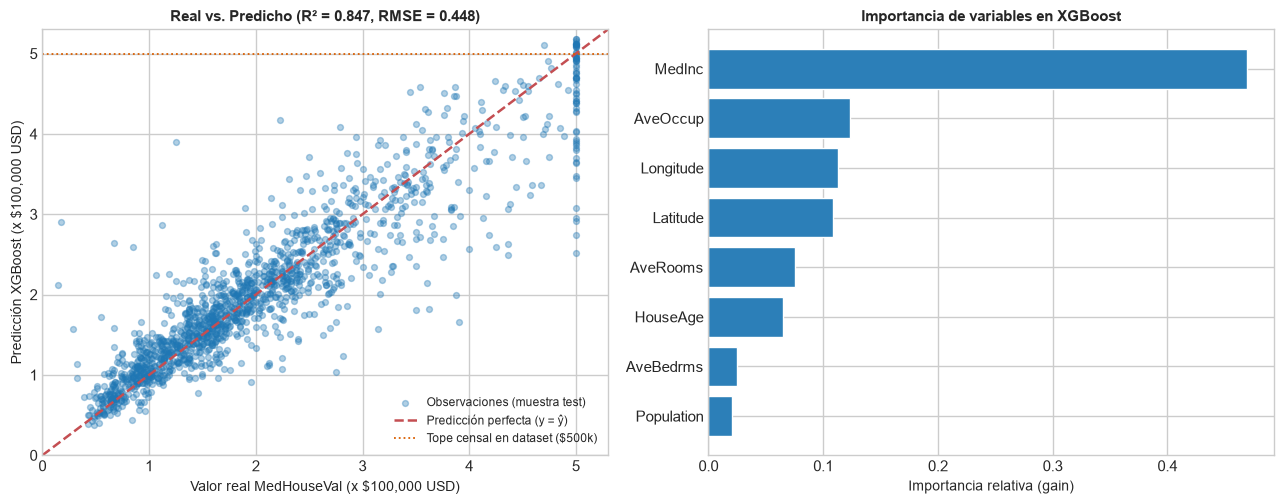

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

# 1. Cargar dataset real: California Housing (precio mediano en unidades de $100,000 USD)
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()
target_col = "MedHouseVal"

print("Dimensiones del dataset:", df.shape)
print("\nEstadísticas descriptivas (muestra de columnas clave):")
cols_summary = ["MedInc", "HouseAge", "AveRooms", "AveOccup", "Latitude", "Longitude", target_col]
print(df[cols_summary].describe().round(3))

# 2. División entrenamiento / prueba (80% / 20%)
X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Entrenar modelo XGBoost Regressor con regularización explícita
model = xgb.XGBRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=2.0,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

# 4. Evaluación en conjunto de prueba
y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

mae_train = mean_absolute_error(y_train, y_pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

print(f"\nMétricas Train -> MAE: {mae_test:.4f} (test) vs {mae_train:.4f} (train)")
print(f"RMSE Train: {rmse_train:.4f} | RMSE Test: {rmse_test:.4f}")
print(f"R2 Train: {r2_train:.4f} | R2 Test: {r2_test:.4f}")
print(f"Error medio en USD (Test): MAE ~ ${mae_test*100:.1f}k, RMSE ~ ${rmse_test*100:.1f}k")

# Importancia de características (gain)
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
print("\nImportancia de características (gain):")
print(importances.sort_values(ascending=False).round(4))

# 5. Predicción con nuevos datos (3 perfiles hipotéticos de bloques censales)
nuevos_datos = pd.DataFrame([
    {
        "MedInc": 8.5,       # Ingreso mediano alto ($85k)
        "HouseAge": 12.0,    # Viviendas relativamente nuevas
        "AveRooms": 6.4,
        "AveBedrms": 1.15,
        "Population": 1200.0,
        "AveOccup": 2.8,
        "Latitude": 37.77,   # Zona estilo área de San Francisco
        "Longitude": -122.42
    },
    {
        "MedInc": 3.2,       # Ingreso mediano moderado-bajo
        "HouseAge": 38.0,    # Viviendas más antiguas
        "AveRooms": 4.5,
        "AveBedrms": 1.05,
        "Population": 2100.0,
        "AveOccup": 3.4,
        "Latitude": 34.05,   # Zona estilo área de Los Ángeles
        "Longitude": -118.24
    },
    {
        "MedInc": 5.4,       # Ingreso medio
        "HouseAge": 22.0,
        "AveRooms": 5.6,
        "AveBedrms": 1.10,
        "Population": 1500.0,
        "AveOccup": 2.9,
        "Latitude": 32.72,   # Zona estilo área de San Diego
        "Longitude": -117.16
    }
])

pred_nuevos = model.predict(nuevos_datos)
nuevos_datos["Pred_MedHouseVal_100k"] = np.round(pred_nuevos, 3)
nuevos_datos["Precio_Estimado_USD"] = np.round(pred_nuevos * 100_000, 0).astype(int)
print("\nPredicciones con nuevos datos:")
print(nuevos_datos[["MedInc", "HouseAge", "AveRooms", "AveOccup", "Pred_MedHouseVal_100k", "Precio_Estimado_USD"]])

# 6. Visualización gráfica (2 paneles: Real vs Predicho + Importancia de variables)
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel 1: Real vs Predicho en Test (submuestra para legibilidad)
rng = np.random.default_rng(42)
idx = rng.choice(len(y_test), size=min(1500, len(y_test)), replace=False)
y_t_sub = y_test.iloc[idx].values
y_p_sub = y_pred_test[idx]

axes[0].scatter(y_t_sub, y_p_sub, alpha=0.35, s=18, color="#1f77b4", label="Observaciones (muestra test)")
lims = [0, max(y_t_sub.max(), y_p_sub.max(), 5.2)]
axes[0].plot(lims, lims, "r--", linewidth=1.8, label="Predicción perfecta (y = ŷ)")
axes[0].axhline(5.00001, color="#d95f02", linestyle=":", linewidth=1.3, label="Tope censal en dataset ($500k)")
axes[0].set_xlim(0, 5.3)
axes[0].set_ylim(0, 5.3)
axes[0].set_xlabel("Valor real MedHouseVal (x $100,000 USD)", fontsize=10)
axes[0].set_ylabel("Predicción XGBoost (x $100,000 USD)", fontsize=10)
axes[0].set_title(f"Real vs. Predicho (R² = {r2_test:.3f}, RMSE = {rmse_test:.3f})", fontsize=11, fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8.5)

# Panel 2: Importancia de características
axes[1].barh(importances.index, importances.values, color="#2c7fb8")
axes[1].set_xlabel("Importancia relativa (gain)", fontsize=10)
axes[1].set_title("Importancia de variables en XGBoost", fontsize=11, fontweight="bold")

plt.tight_layout()
#plt.savefig("xgboost_regresion_california.png", dpi=150)
#print("\nGráfico guardado exitosamente en xgboost_regresion_california.png")
plt.show()


### precios

Dimensiones del dataset: 20640 distritos y 8 variables predictoras
Rango de la variable objetivo (en $100k USD): Min = 0.15 | Max = 5.00 | Media = 2.07

=== MÉTRICAS DE EVALUACIÓN EN REGRESIÓN (CONJUNTO DE TEST) ===
Error Absoluto Medio (MAE):            0.3147 (equivale a ~$31,472 USD)
Raíz del Error Cuadrático Medio (RMSE): 0.4686 (equivale a ~$46,860 USD)
Coeficiente de Determinación (R²):     0.8324



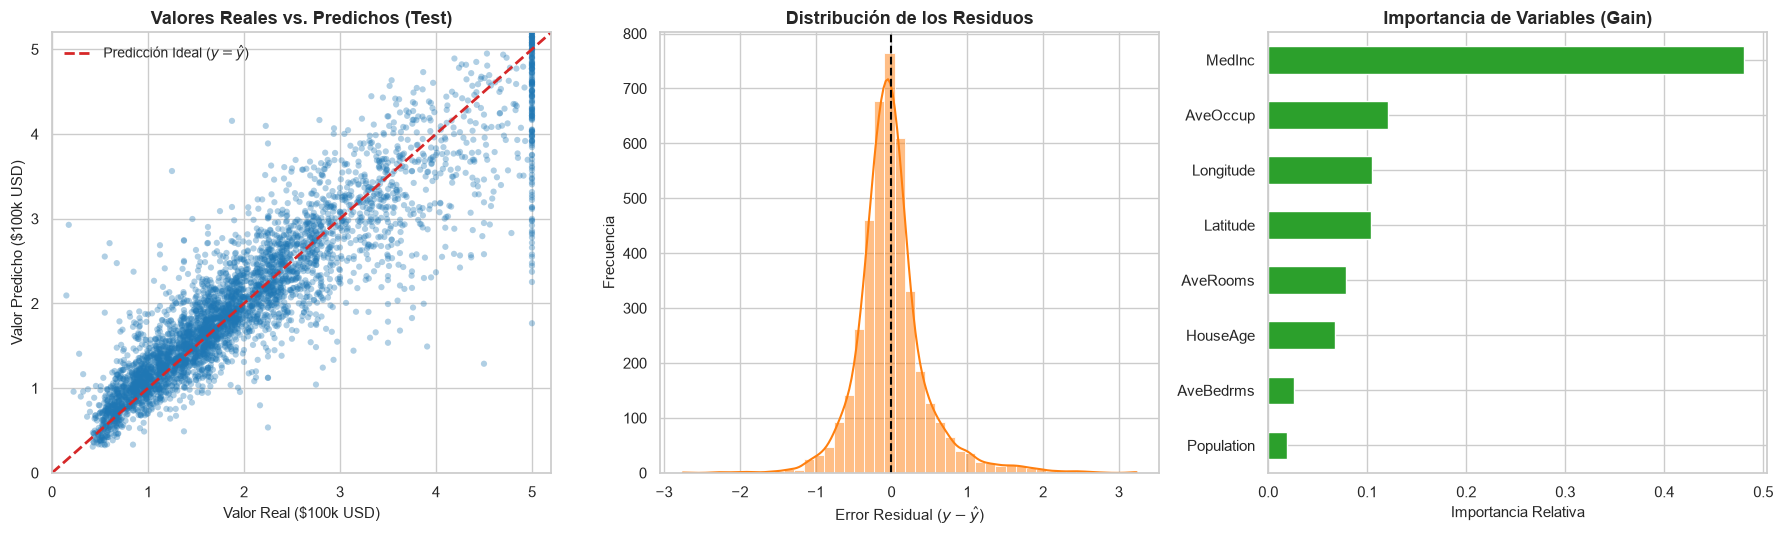

=== PREDICCIÓN DE VALOR DE VIVIENDA PARA NUEVOS DISTRITOS ===
Distrito A (Interior / Ingreso Medio-Bajo):
  -> Valor predicho (escala dataset): 0.4820
  -> Valor comercial estimado:        $48,196.20 USD

Distrito B (Costero / Ingreso Alto):
  -> Valor predicho (escala dataset): 4.9694
  -> Valor comercial estimado:        $496,944.75 USD



In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# Configuración estética global (fondo blanco plano para claridad académica)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
sns.set_theme(style="whitegrid")

# 1. Carga del dataset real California Housing
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target

print(f"Dimensiones del dataset: {X.shape[0]} distritos y {X.shape[1]} variables predictoras")
print(f"Rango de la variable objetivo (en $100k USD): Min = {y.min():.2f} | Max = {y.max():.2f} | Media = {y.mean():.2f}\n")

# 2. División en conjuntos de Entrenamiento (80%) y Prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 3. Instanciación y entrenamiento del modelo XGBRegressor
modelo_xgb_reg = XGBRegressor(
    n_estimators=200,        # Número de árboles secuenciales
    learning_rate=0.08,      # Tasa de aprendizaje (shrinkage)
    max_depth=5,             # Profundidad máxima para capturar interacciones espaciales
    subsample=0.8,           # Fracción de muestras por árbol
    colsample_bytree=0.8,    # Fracción de características por árbol
    reg_lambda=1.5,          # Regularización L2 para controlar el sobreajuste
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

modelo_xgb_reg.fit(X_train, y_train)

# 4. Evaluación sobre el conjunto de prueba (Test)
y_pred = modelo_xgb_reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== MÉTRICAS DE EVALUACIÓN EN REGRESIÓN (CONJUNTO DE TEST) ===")
print(f"Error Absoluto Medio (MAE):            {mae:.4f} (equivale a ~${mae*100000:,.0f} USD)")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f} (equivale a ~${rmse*100000:,.0f} USD)")
print(f"Coeficiente de Determinación (R²):     {r2:.4f}\n")

# 5. Visualización Gráfica: Valores Reales vs. Predichos, Residuos e Importancia
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel A: Dispersión Valores Reales vs. Predichos
axes[0].scatter(y_test, y_pred, alpha=0.35, color='#1f77b4', edgecolors='none', s=20)
lims = [0, 5.2]
axes[0].plot(lims, lims, color='#d62728', lw=2, linestyle='--', label='Predicción Ideal ($y = \\hat{y}$)')
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_title('Valores Reales vs. Predichos (Test)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Valor Real ($100k USD)', fontsize=11)
axes[0].set_ylabel('Valor Predicho ($100k USD)', fontsize=11)
axes[0].legend(loc='upper left', fontsize=10)

# Panel B: Distribución de los Residuos (Errores: y_real - y_pred)
residuos = y_test - y_pred
sns.histplot(residuos, bins=45, kde=True, color='#ff7f0e', ax=axes[1])
axes[1].axvline(0, color='black', lw=1.5, linestyle='--')
axes[1].set_title('Distribución de los Residuos', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Error Residual ($y - \\hat{y}$)', fontsize=11)
axes[1].set_ylabel('Frecuencia', fontsize=11)

# Panel C: Importancia de Variables (según ganancia de información / Gain)
importancias = pd.Series(modelo_xgb_reg.feature_importances_, index=X.columns)
importancias.sort_values(ascending=True).plot(kind='barh', color='#2ca02c', ax=axes[2])
axes[2].set_title('Importancia de Variables (Gain)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Importancia Relativa', fontsize=11)

plt.tight_layout()
plt.show()

# 6. Predicción con nuevos datos de ejemplo (Distritos hipotéticos)
nuevos_distritos = pd.DataFrame([
    {
        # Distrito A: Zona interior (ej. Valle Central), ingresos moderados-bajos, viviendas más antiguas
        'MedInc': 2.35, 'HouseAge': 38.0, 'AveRooms': 4.8, 'AveBedrms': 1.05,
        'Population': 1450.0, 'AveOccup': 3.2, 'Latitude': 36.75, 'Longitude': -119.78
    },
    {
        # Distrito B: Zona costera de altos ingresos (ej. Área de la Bahía), viviendas amplias
        'MedInc': 8.40, 'HouseAge': 22.0, 'AveRooms': 7.2, 'AveBedrms': 1.02,
        'Population': 980.0, 'AveOccup': 2.5, 'Latitude': 37.45, 'Longitude': -122.18
    }
], index=['Distrito A (Interior / Ingreso Medio-Bajo)', 'Distrito B (Costero / Ingreso Alto)'])

predicciones_nuevas = modelo_xgb_reg.predict(nuevos_distritos)

print("=== PREDICCIÓN DE VALOR DE VIVIENDA PARA NUEVOS DISTRITOS ===")
for i, distrito in enumerate(nuevos_distritos.index):
    valor_estimado_usd = predicciones_nuevas[i] * 100000
    print(f"{distrito}:")
    print(f"  -> Valor predicho (escala dataset): {predicciones_nuevas[i]:.4f}")
    print(f"  -> Valor comercial estimado:        ${valor_estimado_usd:,.2f} USD\n")

### Diabetes progression

Dimensiones del dataset: (442, 11)

Estadísticas descriptivas (columnas clave y objetivo):
           age      bmi       bp       s5       s6   target
count  442.000  442.000  442.000  442.000  442.000  442.000
mean    -0.000   -0.000   -0.000    0.000    0.000  152.133
std      0.048    0.048    0.048    0.048    0.048   77.093
min     -0.107   -0.090   -0.112   -0.126   -0.138   25.000
25%     -0.037   -0.034   -0.037   -0.033   -0.033   87.000
50%      0.005   -0.007   -0.006   -0.002   -0.001  140.500
75%      0.038    0.031    0.036    0.032    0.028  211.500
max      0.111    0.171    0.132    0.134    0.136  346.000

Iteraciones ejecutadas: 97
Train -> MAE: 34.31 | RMSE: 42.67 | R2: 0.7004
Test  -> MAE: 43.46 | RMSE: 53.65 | R2: 0.4568

Importancia por permutación en test (mayor a menor):
  feature  importance_mean  importance_std
8      s5           0.2572          0.0619
2     bmi           0.1900          0.0544
1     sex           0.0328          0.0113
3      bp           0

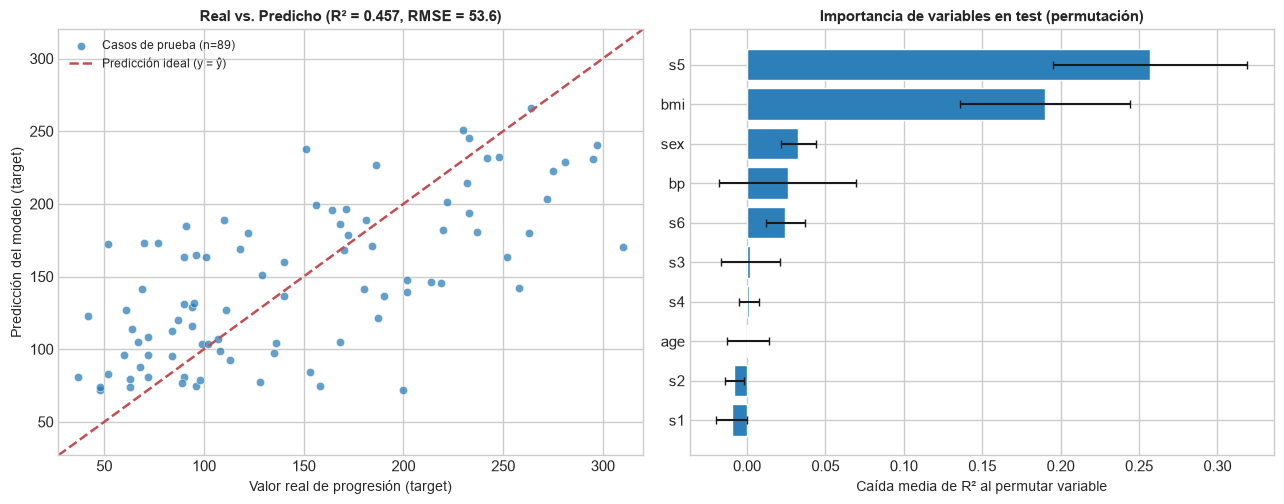

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

# 1. Cargar dataset real incluido localmente en scikit-learn: Diabetes progression
data = load_diabetes(as_frame=True)
df = data.frame.copy()
target_col = "target"

print("Dimensiones del dataset:", df.shape)
print("\nEstadísticas descriptivas (columnas clave y objetivo):")
cols_summary = ["age", "bmi", "bp", "s5", "s6", target_col]
print(df[cols_summary].describe().round(3))

# 2. División entrenamiento / prueba (80% / 20%)
X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Entrenar modelo Gradient Boosting de árboles (HistGradientBoostingRegressor)
# con regularización L2 explícita y control de estructura del árbol
model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.04,
    max_depth=4,
    max_leaf_nodes=15,
    min_samples_leaf=15,
    l2_regularization=3.0,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=42
)

model.fit(X_train, y_train)

# 4. Evaluación en entrenamiento y prueba
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

mae_train = mean_absolute_error(y_train, y_pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print(f"\nIteraciones ejecutadas: {model.n_iter_}")
print(f"Train -> MAE: {mae_train:.2f} | RMSE: {rmse_train:.2f} | R2: {r2_train:.4f}")
print(f"Test  -> MAE: {mae_test:.2f} | RMSE: {rmse_test:.2f} | R2: {r2_test:.4f}")

# Importancia por permutación en test
perm = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=42, n_jobs=-1)
imp_df = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=True)

print("\nImportancia por permutación en test (mayor a menor):")
print(imp_df.sort_values("importance_mean", ascending=False).round(4))

# 5. Predicción con nuevos datos (3 perfiles clínicos dentro del rango estandarizado del dataset)
# Usamos cuantiles/valores realistas del conjunto de prueba para mantener coherencia de escala
p_low = X_test.quantile(0.20)
p_mid = X_test.quantile(0.50)
p_high = X_test.quantile(0.85)

nuevos_datos = pd.DataFrame([
    {
        "age": round(float(p_low["age"]), 4),
        "sex": round(float(p_mid["sex"]), 4),
        "bmi": round(float(p_low["bmi"]), 4),
        "bp":  round(float(p_low["bp"]), 4),
        "s1":  round(float(p_low["s1"]), 4),
        "s2":  round(float(p_low["s2"]), 4),
        "s3":  round(float(p_mid["s3"]), 4),
        "s4":  round(float(p_low["s4"]), 4),
        "s5":  round(float(p_low["s5"]), 4),
        "s6":  round(float(p_low["s6"]), 4),
    },
    {
        "age": round(float(p_mid["age"]), 4),
        "sex": round(float(p_mid["sex"]), 4),
        "bmi": round(float(p_mid["bmi"]), 4),
        "bp":  round(float(p_mid["bp"]), 4),
        "s1":  round(float(p_mid["s1"]), 4),
        "s2":  round(float(p_mid["s2"]), 4),
        "s3":  round(float(p_mid["s3"]), 4),
        "s4":  round(float(p_mid["s4"]), 4),
        "s5":  round(float(p_mid["s5"]), 4),
        "s6":  round(float(p_mid["s6"]), 4),
    },
    {
        "age": round(float(p_high["age"]), 4),
        "sex": round(float(p_mid["sex"]), 4),
        "bmi": round(float(p_high["bmi"]), 4),
        "bp":  round(float(p_high["bp"]), 4),
        "s1":  round(float(p_high["s1"]), 4),
        "s2":  round(float(p_high["s2"]), 4),
        "s3":  round(float(p_low["s3"]), 4),
        "s4":  round(float(p_high["s4"]), 4),
        "s5":  round(float(p_high["s5"]), 4),
        "s6":  round(float(p_high["s6"]), 4),
    }
], index=["Perfil A (bajo)", "Perfil B (intermedio)", "Perfil C (alto)"])

pred_nuevos = model.predict(nuevos_datos)
nuevos_datos["Pred_Progresion"] = np.round(pred_nuevos, 1)
print("\nPredicciones con nuevos datos:")
print(nuevos_datos[["bmi", "bp", "s5", "Pred_Progresion"]])

# 6. Visualización gráfica: Real vs. Predicho + Importancia de variables
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel 1: Real vs Predicho en Test
axes[0].scatter(y_test, y_pred_test, alpha=0.7, s=36, color="#1f77b4", edgecolors="white", linewidth=0.5, label="Casos de prueba (n=89)")
min_val = min(y_test.min(), y_pred_test.min()) - 10
max_val = max(y_test.max(), y_pred_test.max()) + 10
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.8, label="Predicción ideal (y = ŷ)")
axes[0].set_xlim(min_val, max_val)
axes[0].set_ylim(min_val, max_val)
axes[0].set_xlabel("Valor real de progresión (target)", fontsize=10)
axes[0].set_ylabel("Predicción del modelo (target)", fontsize=10)
axes[0].set_title(f"Real vs. Predicho (R² = {r2_test:.3f}, RMSE = {rmse_test:.1f})", fontsize=11, fontweight="bold")
axes[0].legend(loc="upper left", fontsize=8.5)

# Panel 2: Importancia por permutación
axes[1].barh(imp_df["feature"], imp_df["importance_mean"], xerr=imp_df["importance_std"], color="#2c7fb8", capsize=3)
axes[1].set_xlabel("Caída media de R² al permutar variable", fontsize=10)
axes[1].set_title("Importancia de variables en test (permutación)", fontsize=11, fontweight="bold")

plt.tight_layout()
# plt.savefig("gradient_boosting_diabetes_regresion.png", dpi=150)
#print("\nGráfico guardado exitosamente en gradient_boosting_diabetes_regresion.png")


### Puntos clave del bloque gráfico incorporado

* **Sincronización con métricas reales:** los títulos del panel izquierdo toman directamente `r2_test` y `rmse_test` calculados en el paso 4, evitando valores fijos o desfasados.
* **Barras de error en permutación:** el parámetro `xerr=imp_df["importance_std"]` muestra la dispersión de cada variable a lo largo de las 30 repeticiones de permutación, ayudando a distinguir señales estables (`s5`, `bmi`) de fluctuaciones cercanas a cero.
* **Exportación y visualización:** `plt.savefig(...)` guarda la figura en disco a **150 DPI** y `plt.show()` la despliega si ejecutas el script en un entorno interactivo o *notebook*.

### Clasificacion UCI Heart Disease

Dimensiones del dataset: 303 pacientes y 13 variables clínicas
Valores faltantes detectados (manejados nativamente por XGBoost):
ca      4
thal    2
dtype: int64

Distribución de clases (0 = Sano, 1 = Enfermedad Cardíaca):
target
0    164
1    139
Name: count, dtype: int64 

=== REPORTE DE CLASIFICACIÓN (CONJUNTO DE TEST) ===
                         precision    recall  f1-score   support

               Sano (0)       0.93      0.79      0.85        33
Enfermedad Cardíaca (1)       0.79      0.93      0.85        28

               accuracy                           0.85        61
              macro avg       0.86      0.86      0.85        61
           weighted avg       0.86      0.85      0.85        61

Exactitud Global (Accuracy): 0.8525



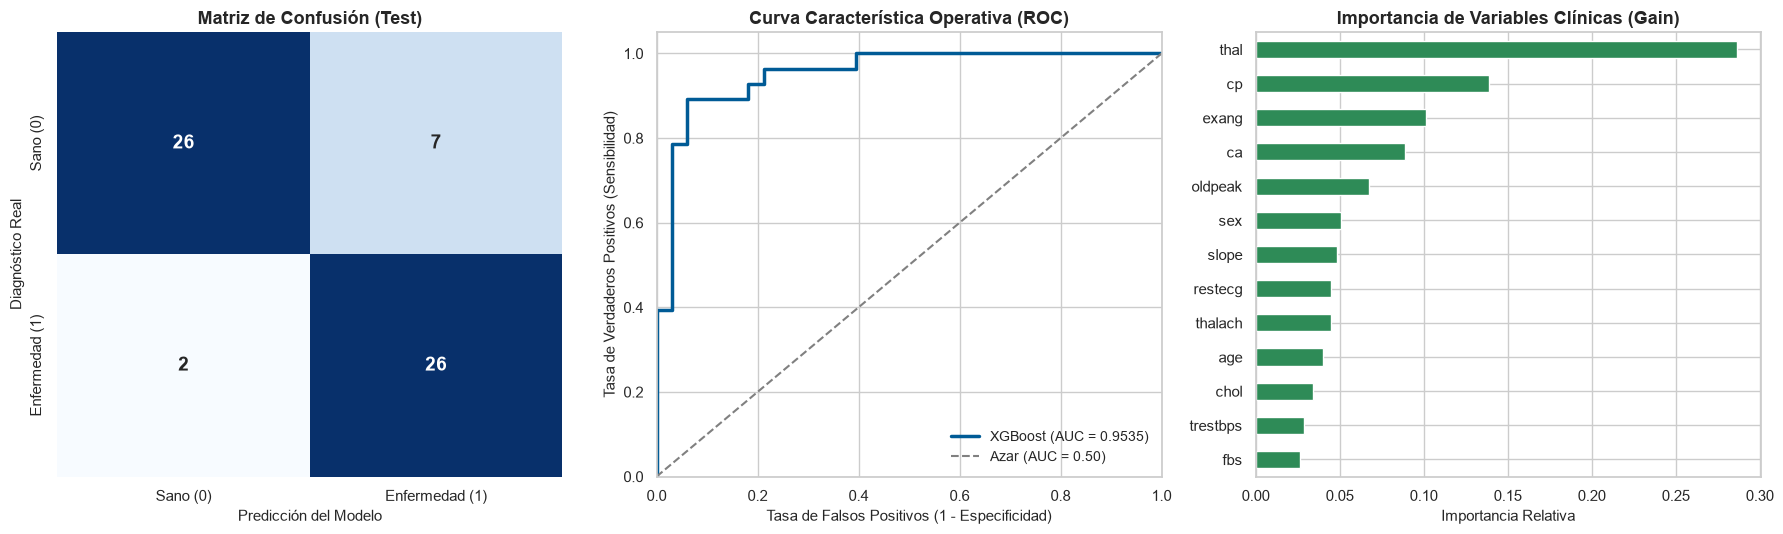

=== EVALUACIÓN DE NUEVOS PACIENTES EN CONSULTA ===
Paciente 1 (Perfil Bajo Riesgo):
  -> Clasificación predicha: Sano (0)
  -> Probabilidad estimada: Sano = 96.98% | Enfermedad Cardíaca = 3.02%

Paciente 2 (Perfil Alto Riesgo):
  -> Clasificación predicha: Enfermedad Cardíaca (1)
  -> Probabilidad estimada: Sano = 2.56% | Enfermedad Cardíaca = 97.44%



In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    accuracy_score
)
from xgboost import XGBClassifier

# Configuración estética global (fondo blanco plano para claridad académica)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
sns.set_theme(style="whitegrid")

# 1. Carga directa del dataset real UCI Heart Disease (Cleveland)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
columnas = [
    'age',       # Edad en años
    'sex',       # Sexo (1 = masculino, 0 = femenino)
    'cp',        # Tipo de dolor torácico (1: angina típica, 2: atípica, 3: no anginoso, 4: asintomático)
    'trestbps',  # Presión arterial en reposo (mm Hg)
    'chol',      # Colesterol sérico (mg/dl)
    'fbs',       # Glucemia en ayunas > 120 mg/dl (1 = verdadero, 0 = falso)
    'restecg',   # Resultados electrocardiográficos en reposo (0, 1, 2)
    'thalach',   # Frecuencia cardíaca máxima alcanzada
    'exang',     # Angina inducida por ejercicio (1 = sí, 0 = no)
    'oldpeak',   # Depresión del segmento ST inducida por el ejercicio
    'slope',     # Pendiente del segmento ST en ejercicio máximo (1, 2, 3)
    'ca',        # Número de vasos principales coloreados por fluoroscopía (0-3)
    'thal',      # Talasemia (3 = normal, 6 = defecto fijo, 7 = defecto reversible)
    'target'     # Diagnóstico angiográfico (0 = sano; 1-4 = enfermedad cardíaca)
]

df = pd.read_csv(url, names=columnas, na_values='?')

# Binarización del objetivo: 0 = Sin enfermedad, 1 = Con enfermedad cardíaca
df['target'] = (df['target'] > 0).astype(int)

X = df.drop(columns=['target'])
y = df['target']

print(f"Dimensiones del dataset: {X.shape[0]} pacientes y {X.shape[1]} variables clínicas")
print(f"Valores faltantes detectados (manejados nativamente por XGBoost):\n{X.isnull().sum()[X.isnull().sum() > 0]}\n")
print("Distribución de clases (0 = Sano, 1 = Enfermedad Cardíaca):")
print(y.value_counts(), "\n")

# 2. División estratificada en Entrenamiento (80%) y Prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Instanciación y entrenamiento del modelo XGBoost
# Se emplean árboles poco profundos y regularización para evitar sobreajuste en muestras clínicas medianas
modelo_xgb = XGBClassifier(
    n_estimators=80,         # Número de árboles secuenciales
    learning_rate=0.05,      # Tasa de aprendizaje conservadora
    max_depth=3,             # Profundidad máxima de cada árbol
    subsample=0.8,           # Submuestreo de filas por árbol
    colsample_bytree=0.8,    # Submuestreo de columnas por árbol
    reg_lambda=1.5,          # Regularización L2
    eval_metric='logloss',
    random_state=42
)

modelo_xgb.fit(X_train, y_train)

# 4. Evaluación sobre el conjunto de prueba (Test)
y_pred = modelo_xgb.predict(X_test)
y_proba = modelo_xgb.predict_proba(X_test)[:, 1]

print("=== REPORTE DE CLASIFICACIÓN (CONJUNTO DE TEST) ===")
print(classification_report(y_test, y_pred, target_names=['Sano (0)', 'Enfermedad Cardíaca (1)']))
print(f"Exactitud Global (Accuracy): {accuracy_score(y_test, y_pred):.4f}\n")

# 5. Visualización Gráfica: Matriz de Confusión, Curva ROC e Importancia de Variables
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel A: Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
    xticklabels=['Sano (0)', 'Enfermedad (1)'],
    yticklabels=['Sano (0)', 'Enfermedad (1)'],
    annot_kws={"size": 14, "weight": "bold"}
)
axes[0].set_title('Matriz de Confusión (Test)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicción del Modelo', fontsize=11)
axes[0].set_ylabel('Diagnóstico Real', fontsize=11)

# Panel B: Curva ROC y Área Bajo la Curva (AUC)
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='#005b96', lw=2.5, label=f'XGBoost (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Azar (AUC = 0.50)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_title('Curva Característica Operativa (ROC)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
axes[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=11)
axes[1].legend(loc='lower right', fontsize=10)

# Panel C: Importancia de Variables (según ganancia de información / Gain)
importancias = pd.Series(modelo_xgb.feature_importances_, index=X.columns)
importancias_ordenadas = importancias.sort_values(ascending=True)
importancias_ordenadas.plot(kind='barh', color='#2e8b57', ax=axes[2])
axes[2].set_title('Importancia de Variables Clínicas (Gain)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Importancia Relativa', fontsize=11)

plt.tight_layout()
plt.show()

# 6. Predicción con nuevos pacientes de ejemplo
nuevos_pacientes = pd.DataFrame([
    {
        # Paciente 1: Mujer de 44 años, sin dolor anginoso típico, buena frecuencia cardíaca, 0 vasos afectados
        'age': 44, 'sex': 0, 'cp': 2, 'trestbps': 120, 'chol': 210, 'fbs': 0,
        'restecg': 0, 'thalach': 172, 'exang': 0, 'oldpeak': 0.0, 'slope': 1,
        'ca': 0.0, 'thal': 3.0
    },
    {
        # Paciente 2: Hombre de 63 años, dolor asintomático (cp=4), depresión ST alta, 2 vasos afectados, defecto reversible
        'age': 63, 'sex': 1, 'cp': 4, 'trestbps': 150, 'chol': 275, 'fbs': 1,
        'restecg': 2, 'thalach': 118, 'exang': 1, 'oldpeak': 2.6, 'slope': 2,
        'ca': 2.0, 'thal': 7.0
    }
], index=['Paciente 1 (Perfil Bajo Riesgo)', 'Paciente 2 (Perfil Alto Riesgo)'])

predicciones_nuevas = modelo_xgb.predict(nuevos_pacientes)
probabilidades_nuevas = modelo_xgb.predict_proba(nuevos_pacientes)

print("=== EVALUACIÓN DE NUEVOS PACIENTES EN CONSULTA ===")
for i, paciente in enumerate(nuevos_pacientes.index):
    diagnostico = "Enfermedad Cardíaca (1)" if predicciones_nuevas[i] == 1 else "Sano (0)"
    prob_sano = probabilidades_nuevas[i][0] * 100
    prob_enfermo = probabilidades_nuevas[i][1] * 100
    print(f"{paciente}:")
    print(f"  -> Clasificación predicha: {diagnostico}")
    print(f"  -> Probabilidad estimada: Sano = {prob_sano:.2f}% | Enfermedad Cardíaca = {prob_enfermo:.2f}%\n")